# Préparation des données pour la prédiction des incendies

**Adam Talibi et Anouar Baoutoul**

Ce travail prépare le jeu de données incendies avant la modélisation : contrôle
de la qualité, gestion des absences, analyse des valeurs atypiques, comparaison
des mises à l'échelle, encodage et séparation temporelle des observations.
Les choix et les méthodes sont détaillés dans
[GUIDE_PRETRAITEMENT.md](../Preparation_Donnees/GUIDE_PRETRAITEMENT.md).

Les transformations alternatives sont comparées séparément. La sélection de
variables, l'ingénierie calendaire et la réduction de dimension complètent
l'analyse, sans modifier automatiquement le pipeline retenu.

**Portée des données.** La source est le CSV figé du projet, issu de détections
satellitaires déclarées FIRMS et de météo Open-Meteo. Les mesures météo
décrivent la même journée que `feu` : nous évaluons une association
rétrospective, pas une prévision J+1. L'export satellitaire brut et la méthode
de construction de `feu=0` restent à documenter. Aucun téléchargement ni
installation réseau n'est nécessaire pour exécuter ce notebook dans
l'environnement du projet déjà installé.

In [13]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Image, Markdown

# Exécution depuis la racine du dépôt ou le dossier de ce notebook.
# Aucun changement du répertoire de travail n'est nécessaire.
candidats = [Path.cwd(), Path.cwd() / "Preparation_Donnees", Path.cwd().parent / "Preparation_Donnees"]
BASE = next((p.resolve() for p in candidats if (p / "pipeline_pretraitement.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Ouvrir le notebook depuis le dépôt, Analyse_et_Modelisation ou Preparation_Donnees.")
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
import pipeline_pretraitement as preparation
from comparaisons import comparer_imputations, comparer_encodages
from aberrants import analyser_aberrants

OUT = BASE / "resultats"
OUT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
print("Source :", preparation.SOURCE)
print("Résultats :", OUT)
print("Interpréteur :", sys.executable)

Source : C:\Users\anoir\Desktop\morocco-wildfire-prediction\Analyse_et_Modelisation\data\dataset_feux_meteo_complete.csv
Résultats : C:\Users\anoir\Desktop\morocco-wildfire-prediction\Preparation_Donnees\resultats
Interpréteur : C:\Users\anoir\Desktop\morocco-wildfire-prediction\.venv\Scripts\python.exe


## 1. Nettoyage et traçabilité des observations

Une base exploitable commence par un schéma cohérent.
Nous contrôlons les types, les dates, l'égalité des dates feu/météo, les
coordonnées, les mois, le jour de l'année et les domaines physiques.
Une pluie négative ou une humidité hors de [0, 100] arrête le traitement.
Une mesure météo extrême physiquement possible reste conservée.

Les doublons exacts peuvent être retirés. Plusieurs lignes contradictoires
pour un même lieu et un même jour demandent un examen. L'empreinte SHA-256
permet d'identifier précisément la source utilisée. Les identifiants, la
date dupliquée et les coordonnées de grille servent à l'audit et ne deviennent
pas automatiquement des prédicteurs.

In [14]:
donnees, rapport = preparation.charger_nettoyer()
display(donnees.head())
display(pd.DataFrame({"type": donnees.dtypes.astype(str)}))
display(pd.DataFrame([{
    "lignes_source": rapport["lignes_source"],
    "lignes_nettoyees": rapport["lignes_nettoyees"],
    "doublons_retires": rapport["doublons_exacts_retires"],
    "extremes_supprimes": rapport["valeurs_extremes_reelles_supprimees"],
    "tous_controles_valides": all(rapport["controles"].values()),
}]))
print("SHA-256 :", rapport["sha256_source"])

,id_observation,lat_c,lon_c,acq_date,feu,mois,jour_annee,date,temperature_2m_max,precipitation_sum,wind_speed_10m_max,humidite_moy,lat_grille,lon_grille
0,651,30.7,-8.4,2018-01-01,1,1,1,2018-01-01,26.9,0.0,8.7,25.0833,30.6854,-8.3844
1,3986,33.9,-6.0,2018-01-01,1,1,1,2018-01-01,16.9,0.0,15.1,86.6667,33.9192,-5.9476
2,13212,33.5,-7.5,2018-01-01,0,1,1,2018-01-01,17.5,0.0,20.5,85.3333,33.4974,-7.4629
3,21769,35.5,-5.5,2018-01-01,0,1,1,2018-01-01,16.0,0.0,8.0,78.5000,35.5360,-5.5456
4,2157,32.8,-5.5,2018-01-02,1,1,2,2018-01-02,21.3,0.0,14.0,33.6250,32.7944,-5.5012


,type
id_observation,int64
lat_c,float64
lon_c,float64
acq_date,datetime64[us]
feu,int64
mois,int64
jour_annee,int64
date,datetime64[us]
temperature_2m_max,float64
precipitation_sum,float64


,lignes_source,lignes_nettoyees,doublons_retires,extremes_supprimes,tous_controles_valides
0,22788,22788,0,0,True


SHA-256 : d9da9116b268b7c891a92c33cf7837e3bf91be3a087346bf86753bbe5474db7c


## 2. Séparer les périodes avant tout apprentissage

L'entraînement ajuste les paramètres, la validation
choisit les variantes et le test évalue le choix figé. Ici, les années fixent
les ensembles : **2018–2023 / 2024 / 2025**. Les dates sont triées et les
identifiants sont disjoints. Un même lieu peut apparaître sur plusieurs années,
donc ce protocole ne prouve pas la généralisation à des lieux nouveaux.

Médianes, moyennes, scalers, catégories apprises, sélection et PCA doivent
tous respecter cette séparation. La météo observée pendant toute une journée
n'est pas disponible au début de cette journée, même avec un découpage temporel.

In [15]:
parties = preparation.repartir(donnees)
train, validation, test = (parties[n] for n in ("train", "validation", "test"))
repartition = preparation.bilan_repartition(parties)
display(repartition)
preparation.exporter(repartition, "repartition_chronologique", OUT)
assert train.acq_date.max() < validation.acq_date.min()
assert validation.acq_date.max() < test.acq_date.min()
assert not set(train.id_observation).intersection(test.id_observation)

,ensemble,lignes,debut,fin,feu_0,feu_1,proportion_feu_1
0,train,17904,2018-01-01,2023-12-31,11582,6322,0.3531
1,validation,2374,2024-01-01,2024-12-31,1550,824,0.3471
2,test,2510,2025-01-01,2025-12-31,1629,881,0.3510


## 3. Absences réelles et statistiques descriptives

On mesure les NaN par colonne avant de choisir un
traitement. Le CSV conservé du projet est complet. Cela décrit le fichier
reçu et ne prouve pas qu'aucune valeur n'a manqué pendant la collecte initiale.

Les statistiques utilisées pour décider des transformations ci-dessous
portent sur le train. Les différences d'unité et l'asymétrie de la pluie
justifient de comparer les méthodes. Les proportions des classes décrivent
cet échantillon et ne représentent pas automatiquement la fréquence réelle
des incendies dans la population.

In [16]:
manquants = pd.DataFrame({
    "variable": donnees.columns,
    "nombre_NaN": donnees.isna().sum().to_numpy(),
    "proportion_NaN": donnees.isna().mean().to_numpy(),
})
display(manquants)
preparation.exporter(manquants, "manquants_reels", OUT)
display(train[preparation.METEO].describe().T)
display(train.feu.value_counts().rename_axis("feu").to_frame("nombre"))

,variable,nombre_NaN,proportion_NaN
0,id_observation,0,0.0
1,lat_c,0,0.0
2,lon_c,0,0.0
3,acq_date,0,0.0
4,feu,0,0.0
5,mois,0,0.0
6,jour_annee,0,0.0
7,date,0,0.0
8,temperature_2m_max,0,0.0
9,precipitation_sum,0,0.0


,count,mean,std,min,25%,50%,75%,max
temperature_2m_max,17904.0,25.9140,7.0099,-0.7000,20.9000,25.9000,30.8000,48.0000
precipitation_sum,17904.0,0.7684,3.2220,0.0000,0.0000,0.0000,0.0000,64.4000
wind_speed_10m_max,17904.0,16.6578,5.8371,3.3000,12.7000,15.8000,19.5000,56.3000
humidite_moy,17904.0,62.7960,18.6637,7.6667,50.1667,66.9583,77.4167,99.9167


,nombre
feu,
0,11582
1,6322


## 4. Comparaison des imputations sur des absences artificielles

Suppression de lignes ou de colonnes, constante,
moyenne, médiane, mode, KNN et régression répondent à des situations différentes.
Le mode convient aux catégories ; la médiane résiste mieux aux extrêmes que
la moyenne. Zéro est une valeur physique pour la pluie : l'utiliser pour
remplacer une absence peut déformer l'information.

**MCAR** : absence indépendante des valeurs. **MAR** : après conditionnement
sur les variables observées, l'absence ne dépend plus de la valeur manquante.
**MNAR** : une dépendance à la valeur non observée subsiste. Un taux de NaN
ne permet pas d'identifier ces mécanismes.

La comparaison prend au maximum 1 200 lignes du train, réserve 20 % à une évaluation
interne et masque environ 5 % des cellules de chaque variable. Les imputateurs
et la standardisation de KNN/régression apprennent sur les donneurs masqués
uniquement. Les vérités masquées réservées servent seulement au calcul de
MAE/RMSE, par variable et dans son unité initiale. Les erreurs en °C et en mm
ne sont pas directement comparables. La régression peut générer des mesures
physiquement peu plausibles, ce qui demande un contrôle supplémentaire.
Avec les paramètres présents, seules 12 cellules sont évaluées par variable :
cette analyse exploratoire ne permet pas un choix robuste de méthode.

In [17]:
imputation = comparer_imputations(train.reset_index(drop=True), OUT)
display(imputation["masquage"])
display(imputation["comparaison"].sort_values(["variable", "MAE"]))
display(imputation["suppression"])
display(imputation["categories"].head(12))
display(Markdown(imputation["note"]))
# Ces copies ne changent aucune valeur du dataset réel.

,variable,lignes_donneurs,absences_donneurs,lignes_évaluation,absences_évaluation,taux_absences_évaluation
0,temperature_2m_max,960,48,240,12,0.05
1,precipitation_sum,960,48,240,12,0.05
2,wind_speed_10m_max,960,48,240,12,0.05
3,humidite_moy,960,48,240,12,0.05


,méthode,variable,cellules_évaluées,MAE,RMSE
23,régression_itérative_standardisée,humidite_moy,12,10.3040,11.3468
11,médiane,humidite_moy,12,11.4861,14.2082
7,moyenne,humidite_moy,12,12.1788,14.3261
15,mode,humidite_moy,12,12.6389,14.6748
19,KNN_standardisé,humidite_moy,12,16.9468,21.6714
3,constante_0,humidite_moy,12,65.9097,67.4030
1,constante_0,precipitation_sum,12,2.1417,3.8355
9,médiane,precipitation_sum,12,2.1417,3.8355
13,mode,precipitation_sum,12,2.1417,3.8355
17,KNN_standardisé,precipitation_sum,12,2.2083,3.7467


,opération,avant,après,éléments_retirés,unité,colonnes_retirées
0,dropna sur les lignes artificiellement incompl...,1200,978,222,lignes,
1,suppression des colonnes avec plus de 50 % de NaN,5,4,1,colonnes,capteur_demo_tres_incomplet


,saison_originale,saison_avec_absences_artificielles,imputation_mode,imputation_catégorie_spécifique,absence_artificielle
17,hiver,NaN,automne,Inconnu,True
154,automne,NaN,automne,Inconnu,True
237,automne,NaN,automne,Inconnu,True
236,été,NaN,automne,Inconnu,True
203,été,NaN,automne,Inconnu,True
166,automne,NaN,automne,Inconnu,True
173,été,NaN,automne,Inconnu,True
115,automne,NaN,automne,Inconnu,True
35,été,NaN,automne,Inconnu,True
146,été,NaN,automne,Inconnu,True


Absences artificielles MCAR sur des copies : environ 5 % par variable, graine 42. Les 20 % réservés à l'évaluation interne appartiennent exclusivement au train du projet. Leurs vérités masquées ne participent à aucun ajustement. Les MAE/RMSE portent uniquement sur ces cellules, séparément par variable et dans les unités d'origine. MCAR signifie une absence indépendante des valeurs ; MAR une absence conditionnelle aux variables observées ; MNAR une dépendance résiduelle à la valeur non observée. Le mécanisme réel ne peut pas être déduit de cette simulation ou de l'absence actuelle de NaN. Les seuils de suppression sont des repères à adapter au contexte. Aucun de ces essais n'impose une imputation au dataset réel.

## 5. Encodage nominal, cible et ordre explicite

**OneHotEncoder** transforme la saison en colonnes
binaires sans distance numérique arbitraire entre saisons. L'encodeur apprend
sur le train ; une catégorie inconnue peut être ignorée sans nouveau fit.

**LabelEncoder** illustre ici une copie textuelle de la cible, puis un retour
vers des codes. Son usage scikit-learn concerne `y`. Un ordre métier parmi les
variables `X` doit être fourni explicitement à **OrdinalEncoder**.

L'ordre `faible < moyenne < élevée` utilise des classes d'humidité exploratoires
(≤ 30 %, puis ≤ 60 %, puis > 60 %). Il ne définit pas des niveaux validés de
risque d'incendie. Le pipeline final conserve l'humidité continue et la cible
originale `feu` en 0/1.

In [18]:
encodage = comparer_encodages(train, OUT)
for titre, cle in [
    ("OneHotEncoder : saisons", "onehot"),
    ("Catégorie inconnue", "onehot_inconnu"),
    ("LabelEncoder : copie de la cible", "label"),
    ("Correspondance des classes", "classes_label"),
    ("OrdinalEncoder : ordre défini", "ordinal"),
]:
    display(Markdown(f"**{titre}**"))
    display(encodage[cle])

**OneHotEncoder : saisons**

,saison,saison_automne,saison_hiver,saison_printemps,saison_été
0,hiver,0.0,1.0,0.0,0.0
1,printemps,0.0,0.0,1.0,0.0
2,été,0.0,0.0,0.0,1.0
3,automne,1.0,0.0,0.0,0.0


**Catégorie inconnue**

,saison,saison_automne,saison_hiver,saison_printemps,saison_été
0,saison_inconnue_demo,0.0,0.0,0.0,0.0


**LabelEncoder : copie de la cible**

,feu_original,cible_texte_demo,LabelEncoder_demo
0,0,absence_detection,0
1,1,detection,1


**Correspondance des classes**

,classe,code
0,absence_detection,0
1,detection,1


**OrdinalEncoder : ordre défini**

,humidite_moy_originale,classe_humidite_demo,OrdinalEncoder_demo
0,25.0833,faible,0.0
1,86.6667,élevée,2.0
2,85.3333,élevée,2.0
3,78.5000,élevée,2.0
4,33.6250,moyenne,1.0
5,68.0417,élevée,2.0
6,47.1667,moyenne,1.0
7,22.0000,faible,0.0
8,68.6667,élevée,2.0
9,36.3750,moyenne,1.0


## 6. Valeurs atypiques : diagnostic et alternatives

Le Z-score vaut `z = (x − moyenne_train) / écart_type_train`, avec
`ddof=0`. Nous signalons `|z| > 3` et montrons la zone de vigilance 2–3.
Les bornes IQR sont `Q1 − 1,5 × (Q3−Q1)` et `Q3 + 1,5 × (Q3−Q1)`.
Un signal statistique demande un examen et ne démontre pas une erreur.

**Cas particulier de la pluie :** `Q1 = Q3 = 0` rend l'IQR nul. Une application
aveugle signalerait toute pluie positive et le capping pourrait effacer toutes
les précipitations. Nous gardons les observations réelles et comparons les
suppressions hypothétiques, le capping, `log1p` et la racine sur des copies.

Les boxplots et le nuage température/humidité complètent le diagnostic.
Isolation Forest, LOF et distance KNN sont comparés
sur au maximum 3 000 lignes du seul train, standardisées sur cet
échantillon. Le seuil KNN au quantile 95 est exploratoire et ne fournit pas
une vérité terrain. Une météo extrême plausible peut être utile au modèle.

,variable,n_train,moyenne_train,ecart_type_train_ddof0,q1_train,q3_train,iqr_train,borne_iqr_basse,borne_iqr_haute,n_signal_z_sup3,n_zone_z_2_a_3,n_signal_iqr,iqr_nul,interpretation,borne_capping_basse,borne_capping_haute,n_modifiees_capping_simule
0,temperature_2m_max,17904,25.9140,7.0097,20.9000,30.8000,9.90,6.0500,45.6500,28,752,61,False,"Signal statistique à examiner, pas une preuve ...",6.0500,45.65,61
1,precipitation_sum,17904,0.7684,3.2219,0.0000,0.0000,0.00,0.0000,0.0000,377,208,3825,True,IQR nul : toute valeur différente des quartile...,0.0000,0.00,3825
2,wind_speed_10m_max,17904,16.6578,5.8369,12.7000,19.5000,6.80,2.5000,29.7000,234,567,596,False,"Signal statistique à examiner, pas une preuve ...",2.5000,29.70,596
3,humidite_moy,17904,62.7960,18.6632,50.1667,77.4167,27.25,9.2917,118.2917,0,772,5,False,"Signal statistique à examiner, pas une preuve ...",9.2917,100.00,5


,scenario,n_train_initial,n_exclues_si_applique,n_restantes_si_applique,applique_aux_donnees_reelles
0,suppression_si_signal_iqr,17904,4242,13662,False
1,suppression_si_signal_z_sup3,17904,606,17298,False


,scenario,variable,effectif,minimum,maximum,moyenne,ecart_type_population,asymetrie_skew
0,original_train,temperature_2m_max,17904,-0.7000,48.0000,25.9140,7.0097,0.0641
1,original_train,precipitation_sum,17904,0.0000,64.4000,0.7684,3.2219,7.5718
2,original_train,wind_speed_10m_max,17904,3.3000,56.3000,16.6578,5.8369,1.1934
3,original_train,humidite_moy,17904,7.6667,99.9167,62.7960,18.6632,-0.6511
4,capping_iqr_copie_exploratoire,temperature_2m_max,17904,6.0500,45.6500,25.9162,6.9939,0.0735
5,capping_iqr_copie_exploratoire,precipitation_sum,17904,0.0000,0.0000,0.0000,0.0000,NaN
6,capping_iqr_copie_exploratoire,wind_speed_10m_max,17904,3.3000,29.7000,16.4995,5.3369,0.6280
7,capping_iqr_copie_exploratoire,humidite_moy,17904,9.2917,99.9167,62.7962,18.6627,-0.6510
8,log1p_copie_exploratoire,precipitation_sum,17904,0.0000,4.1805,0.2185,0.5920,3.2431
9,log1p_copie_exploratoire,wind_speed_10m_max,17904,1.4586,4.0483,2.8204,0.3177,0.0380


,methode,n_train_total,n_echantillon_train,seed_echantillon,n_signalees,interpretation
0,IsolationForest_contamination_auto,17904,3000,42,391,"Atypie relative à cet échantillon, à examiner."
1,LOF_20_voisins_contamination_auto,17904,3000,42,58,"Atypie relative à cet échantillon, à examiner."
2,KNN_seuil_quantile_95_exploratoire,17904,3000,42,150,"Atypie relative à cet échantillon, à examiner."


,id_observation,zscore_temperature_2m_max,signal_z_sup3_temperature_2m_max,zone_z_2_a_3_temperature_2m_max,signal_iqr_temperature_2m_max,zscore_precipitation_sum,signal_z_sup3_precipitation_sum,zone_z_2_a_3_precipitation_sum,signal_iqr_precipitation_sum,zscore_wind_speed_10m_max,signal_z_sup3_wind_speed_10m_max,zone_z_2_a_3_wind_speed_10m_max,signal_iqr_wind_speed_10m_max,zscore_humidite_moy,signal_z_sup3_humidite_moy,zone_z_2_a_3_humidite_moy,signal_iqr_humidite_moy,signal_z_au_moins_une_variable,signal_iqr_au_moins_une_variable
0,651,0.1407,False,False,False,-0.2385,False,False,False,-1.3634,False,False,False,-2.0207,False,True,False,False,False
1,3986,-1.2859,False,False,False,-0.2385,False,False,False,-0.2669,False,False,False,1.2790,False,False,False,False,False
2,13212,-1.2003,False,False,False,-0.2385,False,False,False,0.6583,False,False,False,1.2076,False,False,False,False,False
3,21769,-1.4143,False,False,False,-0.2385,False,False,False,-1.4833,False,False,False,0.8414,False,False,False,False,False
4,2157,-0.6582,False,False,False,-0.2385,False,False,False,-0.4553,False,False,False,-1.5630,False,False,False,False,False


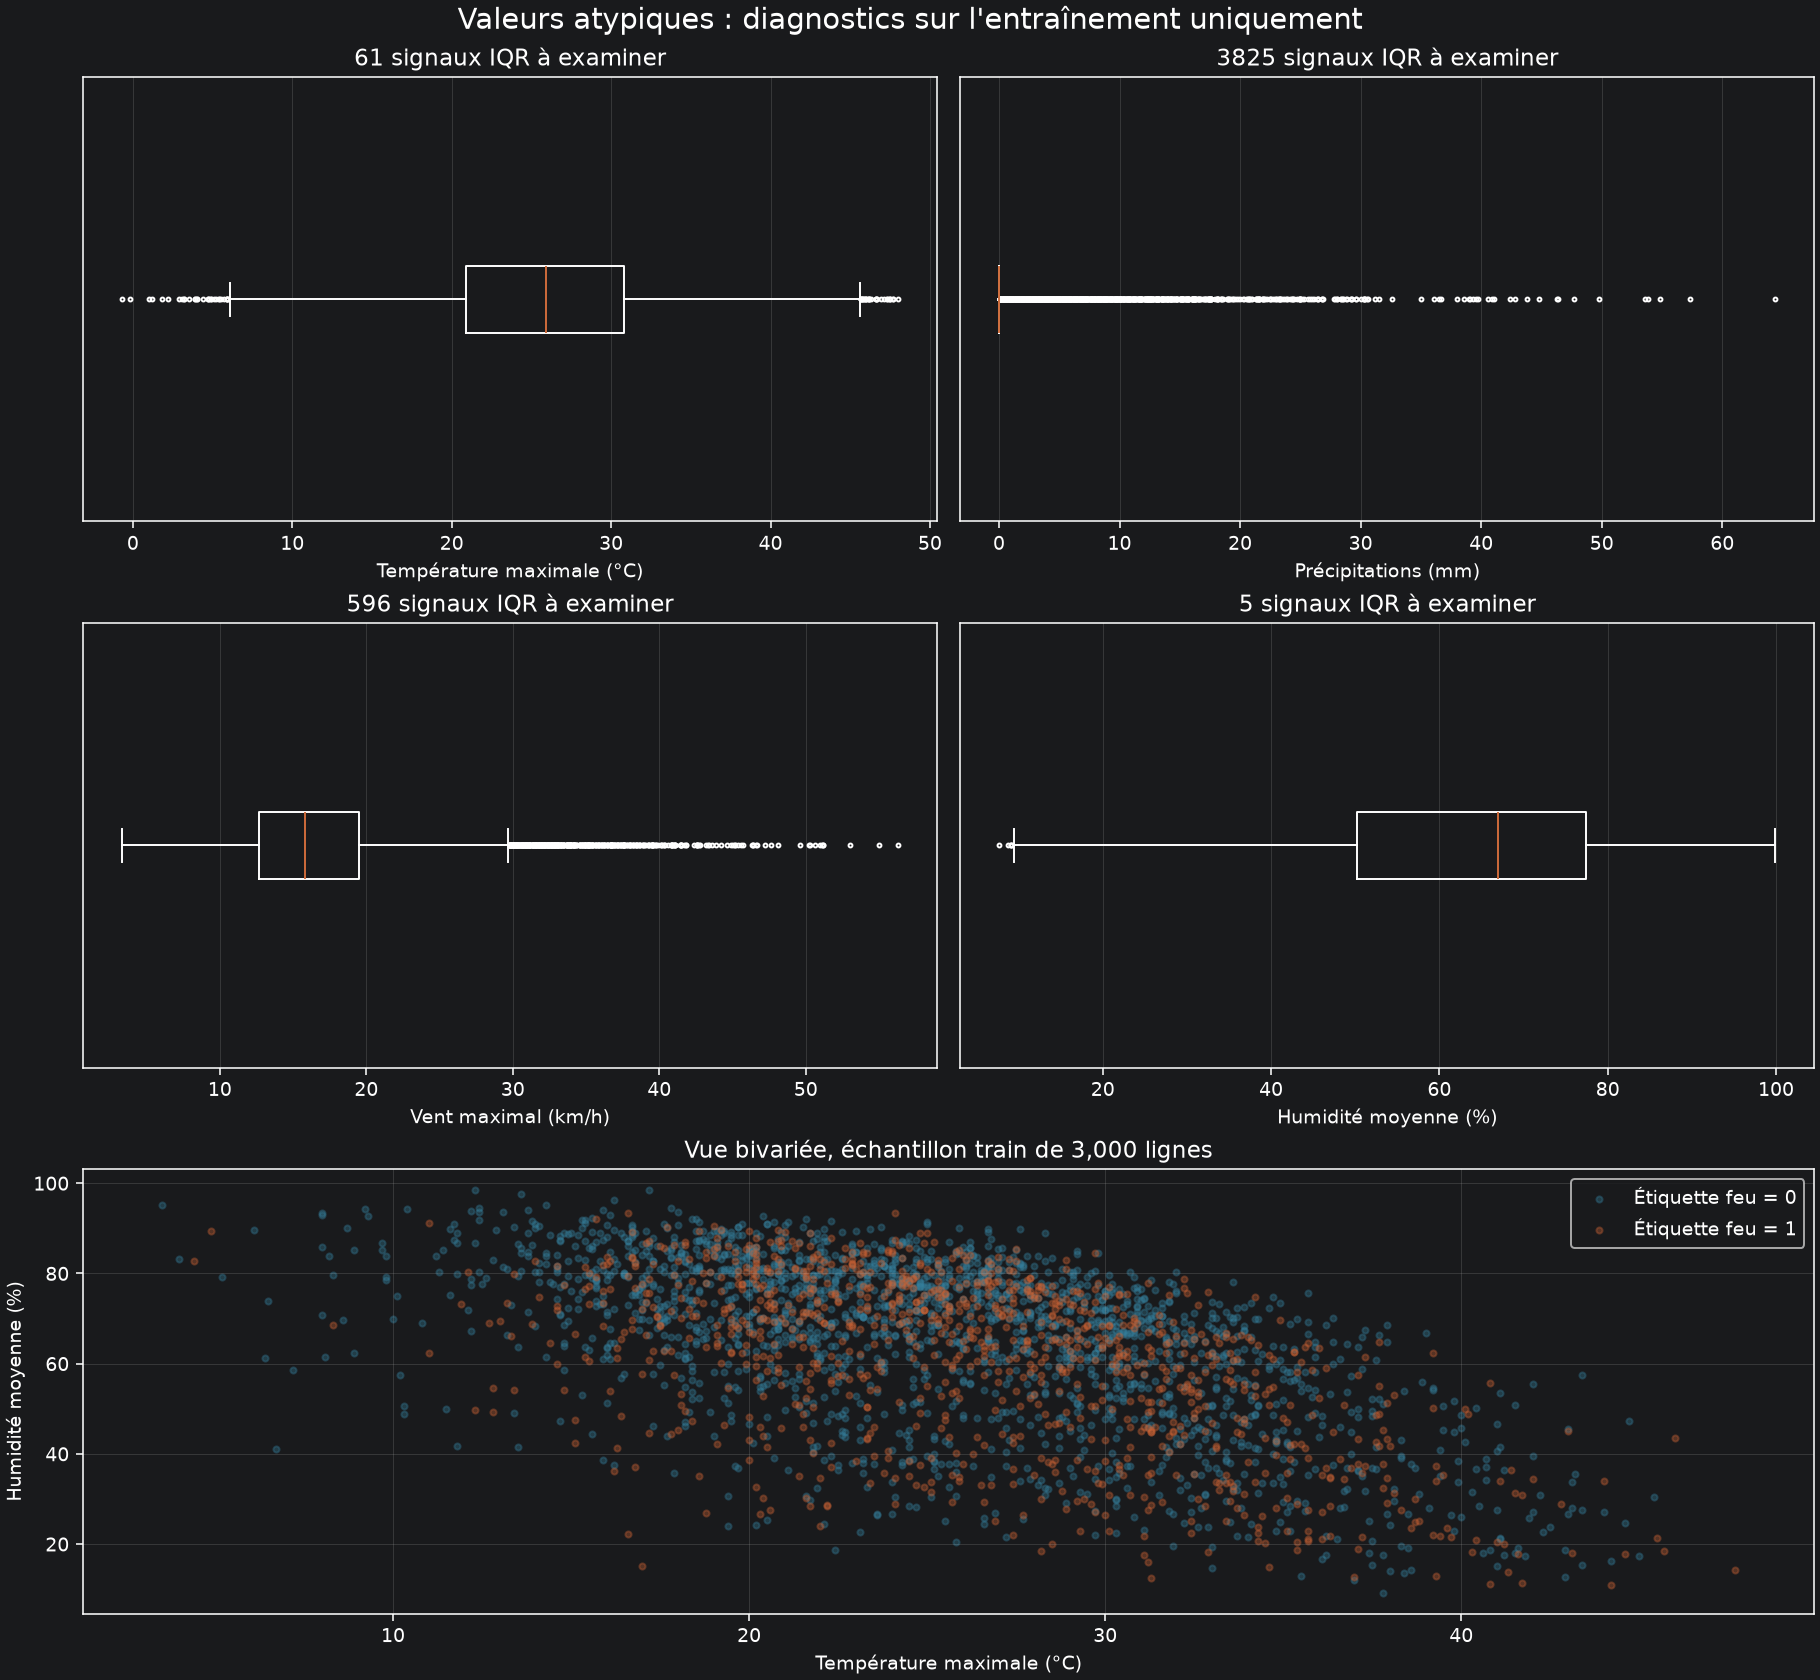

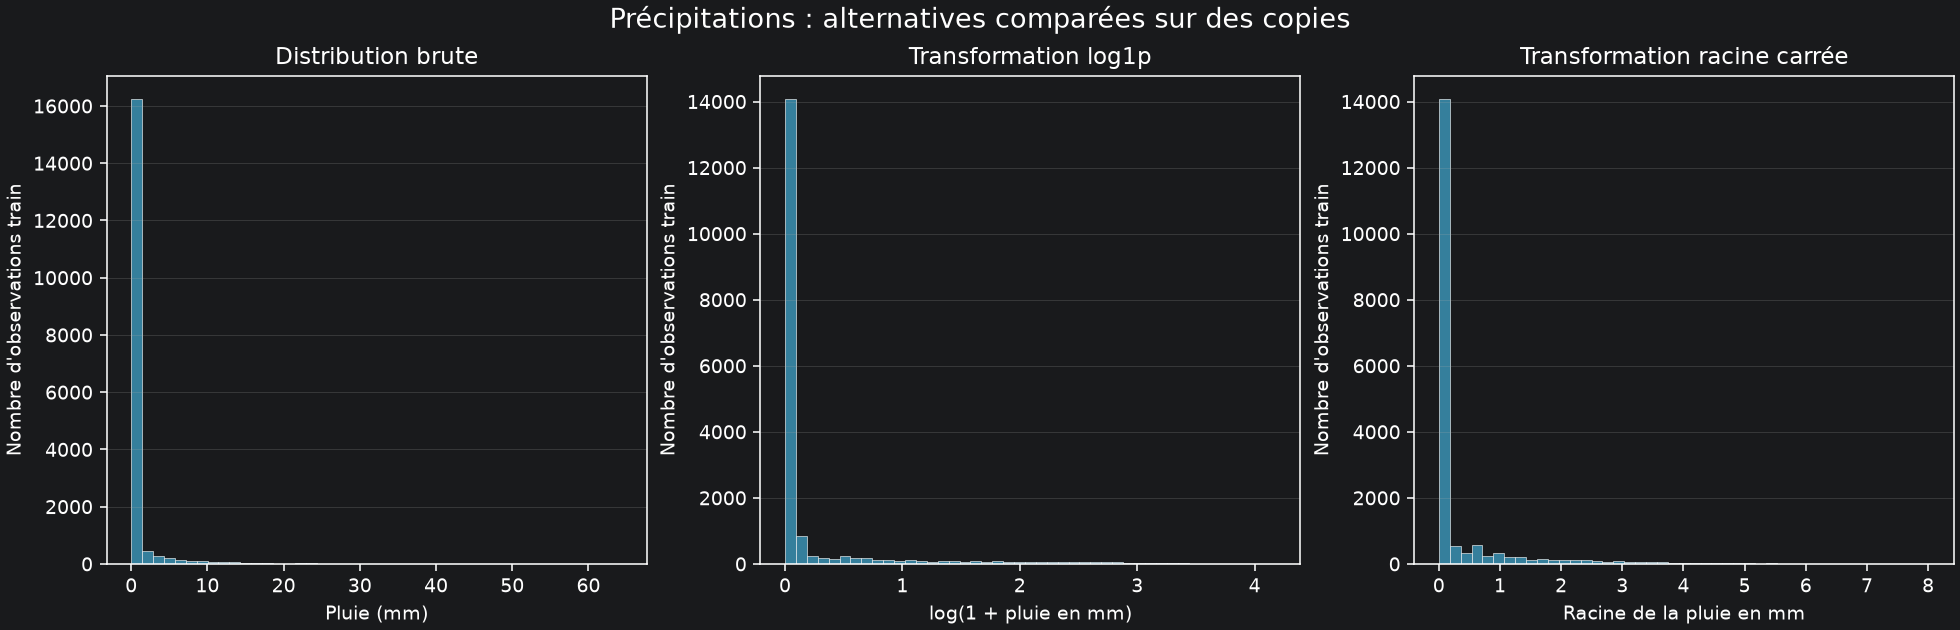

In [19]:
aberrants = analyser_aberrants(train, OUT)
display(aberrants["bornes_aberrants_train"])
display(aberrants["suppression_aberrants_scenarios"])
display(aberrants["stats_transformations_aberrants"])
display(aberrants["synthese_aberrants_multivaries"])
display(aberrants["flags_aberrants_train"].head())
display(Image(filename=str(OUT / "aberrants_boxplots_et_dispersion.png"), width=900))
display(Image(filename=str(OUT / "aberrants_histogrammes_pluie.png"), width=1000))

µ## 7. Mise à l'échelle et caractéristiques calendaires

Pour une variable non constante,
les paramètres suivants viennent exclusivement du train :

| Alternative | Formule usuelle | Lecture |
| --- | --- | --- |
| StandardScaler | `(x − moyenne) / écart_type` | Moyenne 0, écart-type population 1 sur le train |
| MinMaxScaler | `(x − min) / (max − min)` | Train dans [0, 1] |
| MaxAbsScaler | `x / max(abs(x))` | Zéros conservés, train dans [−1, 1] |
| RobustScaler | `(x − médiane) / (Q3 − Q1)` | Centrage robuste, sans intervalle garanti |

RobustScaler centre sur la **médiane**. StandardScaler utilise `ddof=0` et ne rend
pas la distribution gaussienne. Pour une dispersion nulle, scikit-learn évite
la division par zéro. Des données futures peuvent sortir de [0, 1] avec MinMax.
On compare les scalers séparément et on ne les réajuste pas sur la validation.

L'ingénierie calendaire ajoute la saison et deux coordonnées cycliques du jour
de l'année. Le sinus/cosinus exprime la proximité entre fin décembre et début
janvier et tient compte des années bissextiles. Ces dérivations n'utilisent
aucune étiquette. Aucun décalage de lignes n'invente une météo J−1 : la table
n'est pas une série quotidienne complète par lieu.

In [20]:
µµµµechelles = preparation.comparer_echelles(train, OUT)
display(echelles)
standard = echelles[echelles.methode.eq("standard")]
np.testing.assert_allclose(standard.moyenne, 0, atol=1e-12)
np.testing.assert_allclose(standard.ecart_type_ddof0, 1, atol=1e-12)
caracteristiques = preparation.construire_caracteristiques(train[preparation.ENTREES].head(8))
display(caracteristiques)
print("Entrées brutes :", preparation.ENTREES)
print("Caractéristiques dérivées :", caracteristiques.columns.tolist())

,methode,variable,min,max,moyenne,ecart_type_ddof0,mediane,iqr
0,sans_mise_echelle,temperature_2m_max,-0.7000,48.0000,2.5914e+01,7.0097,25.9000,9.9000
1,sans_mise_echelle,precipitation_sum,0.0000,64.4000,7.6836e-01,3.2219,0.0000,0.0000
2,sans_mise_echelle,wind_speed_10m_max,3.3000,56.3000,1.6658e+01,5.8369,15.8000,6.8000
3,sans_mise_echelle,humidite_moy,7.6667,99.9167,6.2796e+01,18.6632,66.9583,27.2500
4,standard,temperature_2m_max,-3.7967,3.1508,1.7144e-16,1.0000,-0.0020,1.4123
5,standard,precipitation_sum,-0.2385,19.7496,-3.1749e-18,1.0000,-0.2385,0.0000
6,standard,wind_speed_10m_max,-2.2885,6.7917,9.6834e-17,1.0000,-0.1470,1.1650
7,standard,humidite_moy,-2.9539,1.9890,1.2065e-16,1.0000,0.2230,1.4601
8,minmax,temperature_2m_max,0.0000,1.0000,5.4649e-01,0.1439,0.5462,0.2033
9,minmax,precipitation_sum,0.0000,1.0000,1.1931e-02,0.0500,0.0000,0.0000


,lat_c,lon_c,temperature_2m_max,precipitation_sum,wind_speed_10m_max,humidite_moy,jour_sin,jour_cos,saison
0,30.7,-8.4,26.9,0.0,8.7,25.0833,0.0000,1.0000,hiver
1,33.9,-6.0,16.9,0.0,15.1,86.6667,0.0000,1.0000,hiver
2,33.5,-7.5,17.5,0.0,20.5,85.3333,0.0000,1.0000,hiver
3,35.5,-5.5,16.0,0.0,8.0,78.5000,0.0000,1.0000,hiver
4,32.8,-5.5,21.3,0.0,14.0,33.6250,0.0172,0.9999,hiver
5,33.4,-7.8,17.1,0.0,22.2,68.0417,0.0172,0.9999,hiver
6,35.1,-3.8,20.4,0.0,14.1,47.1667,0.0172,0.9999,hiver
7,31.9,-4.5,19.6,0.0,10.7,22.0000,0.0172,0.9999,hiver


Entrées brutes : ['lat_c', 'lon_c', 'acq_date', 'temperature_2m_max', 'precipitation_sum', 'wind_speed_10m_max', 'humidite_moy']
Caractéristiques dérivées : ['lat_c', 'lon_c', 'temperature_2m_max', 'precipitation_sum', 'wind_speed_10m_max', 'humidite_moy', 'jour_sin', 'jour_cos', 'saison']


## 8. Pipeline et exemples de répartition reproductibles

Le pipeline reçoit des observations brutes en unités d'origine. Il dérive les
caractéristiques, impute les numériques par médiane, applique le scaler choisi,
impute la saison puis l'encode et entraîne une régression logistique pondérée.
`ColumnTransformer` permet des traitements différents selon le type de colonne.
Dans le modèle final, une saison de référence est retirée par `drop="first"`.

La partition `train_test_split(test_size=0.2,
random_state=42, stratify=y)` et le k-fold stratifié sont exécutés **à l'intérieur
du train uniquement**. La graine rend la partition reproductible ; `stratify`
maintient approximativement la proportion des classes. Ces exemples ne
remplacent pas la séparation temporelle principale. En validation croisée de
modèles, placer les transformations apprises dans le pipeline pour les réajuster
à l'intérieur de chaque pli d'apprentissage.

In [21]:
exemple_pipeline = preparation.creer_pipeline("standard", log_pluie=False)
display(exemple_pipeline)
repartitions_comparees = preparation.comparer_repartitions(train, OUT)
display(repartitions_comparees)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('caracteristiques', ...), ('preparation', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function con...001E0F4B91EE0>
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",{'log_pluie': False}
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined i

,exemple,partie,lignes,proportion_feu_1
0,80_20_stratifie_train_uniquement,80%,14323,0.3531
1,80_20_stratifie_train_uniquement,20%,3581,0.3530
2,kfold_stratifie_interne_1,controle,5968,0.3532
3,kfold_stratifie_interne_2,controle,5968,0.3530
4,kfold_stratifie_interne_3,controle,5968,0.3530


## 9. Validation chronologique interne et analyse des caractéristiques

Les fenêtres annuelles internes entraînent sur les années précédentes et
contrôlent successivement 2022 puis 2023. Aucun pli ne mélange les observations
d'une même journée entre passé et futur, et chaque pipeline est réappris sur
son passé. Ces fenêtres restent au sein de 2018–2023.

L'analyse des caractéristiques compare deux représentations complémentaires :
SelectKBest fournit des scores F univariés et PCA conserve 95 % de la variance
après préparation. La PCA mélange les variables et peut réduire leur
interprétabilité. Variance expliquée ou score univarié ne prouvent pas une
meilleure prédiction. Ces analyses ne changent pas le pipeline final et ne
consultent ni la validation ni le test.

In [22]:
fenetres = preparation.validation_temporelle_interne(train, OUT)
display(fenetres)
extensions = preparation.extensions_selection_pca(train, OUT)
display(extensions["selection"])
display(extensions["pca"])

,apprentissage_fin,controle_annee,n_train,n_controle,roc_auc,average_precision,balanced_accuracy,precision,rappel,f1
0,2021,2022,11783,3040,0.6003,0.4450,0.5613,0.3994,0.7362,0.5178
1,2022,2023,14823,3081,0.6022,0.4349,0.5732,0.4111,0.6749,0.5109


,variable,score_F,retenue_demo
3,num__precipitation_sum,266.8442,True
5,num__humidite_moy,226.2276,True
2,num__temperature_2m_max,71.9347,True
4,num__wind_speed_10m_max,3.5998,True
1,num__lon_c,3.5342,True
0,num__lat_c,0.3025,True
8,cat__saison_ete,0.2948,False
7,num__jour_cos,0.0978,False
10,cat__saison_printemps,0.0615,False
6,num__jour_sin,0.0061,False


,composante,variance_expliquee,variance_cumulee
0,1,0.2674,0.2674
1,2,0.2133,0.4807
2,3,0.1457,0.6264
3,4,0.1236,0.7500
4,5,0.0994,0.8494
5,6,0.0794,0.9289
6,7,0.0289,0.9578


## 10. Choix du prétraitement sur la validation 2024

Nous comparons sept configurations avec le même modèle : absence de mise à
l'échelle, Standard, MinMax, MaxAbs, Robust, puis Standard et Robust avec
`log1p(pluie)`. Chaque pipeline est ajusté uniquement sur 2018–2023 et évalué
sur 2024. Les transformations logarithmiques et les scalers répondent à des
objectifs différents : distribution pour les premières, unités pour les seconds.

Le critère de choix est **average precision**, puis ROC-AUC pour départager.
L'average precision résume le classement précision/rappel et dépend aussi de
la proportion des classes. Précision, rappel, F1 et balanced accuracy sont
fournis au seuil fixé 0,5. La validation sert au choix ; aucune configuration
n'est choisie en regardant son résultat de test. Le classement obtenu dépend
des données et du modèle : aucun scaler n'est universellement meilleur.

In [23]:
pipeline_retenu, comparaison, choix = preparation.comparer_sur_validation(parties, OUT)
display(comparaison)
print("Configuration choisie sur 2024 :", choix)
print("Paramètres appris uniquement sur 2018–2023 ; seuil fixé à 0,5.")

,configuration,roc_auc,average_precision,balanced_accuracy,precision,rappel,f1
0,standard_log1p_pluie,0.5880,0.4033,0.5584,0.3947,0.6323,0.4860
1,robust_log1p_pluie,0.5878,0.4033,0.5606,0.3965,0.6347,0.4881
2,standard_brut,0.5805,0.3968,0.5499,0.3916,0.5740,0.4656
3,robust_brut,0.5805,0.3968,0.5499,0.3914,0.5752,0.4658
4,sans_mise_echelle_brut,0.5804,0.3967,0.5499,0.3914,0.5752,0.4658
5,minmax_brut,0.5786,0.3952,0.5592,0.4021,0.5655,0.4700
6,maxabs_brut,0.5786,0.3927,0.5542,0.3982,0.5510,0.4623


Configuration choisie sur 2024 : standard_log1p_pluie
Paramètres appris uniquement sur 2018–2023 ; seuil fixé à 0,5.


## 11. Évaluation finale 2025 et réutilisation sur entrées brutes

Le choix est maintenant figé. Le test 2025 évalue ce pipeline et une référence
prédisant la fréquence du train. Nous ne réajustons pas les paramètres sur 2024.
Les exports `X_train`, `X_validation`, `X_test` sont accompagnés de leurs
identifiants et de leurs cibles pour conserver l'alignement des observations.

`pipeline_complet.joblib` regroupe prétraitement et modèle. Le rechargement
doit reproduire les prédictions à partir des colonnes **brutes** : aucun nouveau
scaler ne doit être ajusté sur les matrices déjà transformées. Le module
`pipeline_pretraitement.py` doit rester accessible lors du rechargement.

L'exécution de référence retient StandardScaler avec log1p(pluie) et obtient
environ 0,586 de ROC-AUC et 0,412 d'average precision en 2025 : ces résultats
restent modestes. Les tableaux exécutés ci-dessous donnent les valeurs calculées.
Les scores de cet échantillon ne sont pas une calibration du risque réel dans
la population. Une absence satellitaire ne garantit pas l'absence d'incendie et
une détection thermique ne prouve pas le caractère forestier du feu. Le rapport
conserve ces limites, ainsi que les réserves de localisation et d'horizon.

,modele,roc_auc,average_precision,balanced_accuracy,precision,rappel,f1
0,standard_log1p_pluie,0.5861,0.4117,0.564,0.4039,0.6345,0.4936
1,reference_frequence_train,0.5000,0.3510,0.500,0.0000,0.0000,0.0000


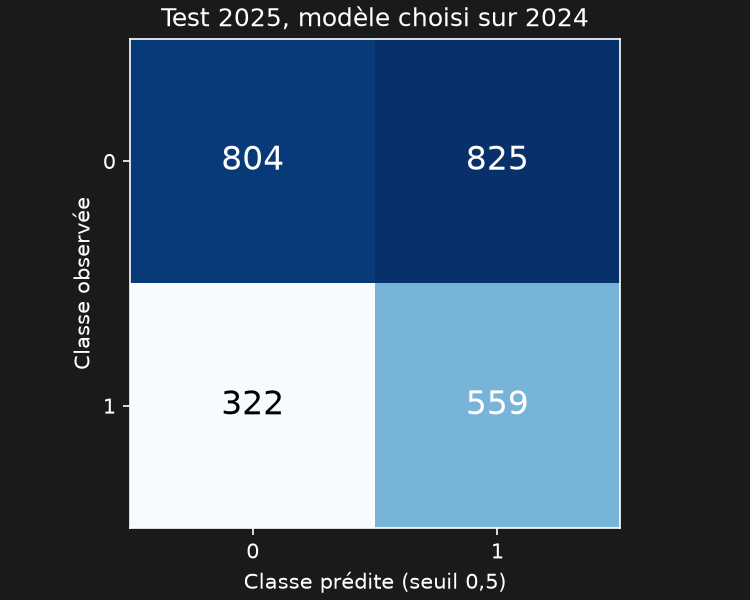

,lat_c,lon_c,acq_date,temperature_2m_max,precipitation_sum,wind_speed_10m_max,humidite_moy,score_modele_recharge
20278,31.6,-8.1,2025-01-01,18.0,0.0,11.3,68.4167,0.4931
20279,32.5,-6.5,2025-01-01,16.8,0.0,10.7,55.9583,0.5290
20280,33.0,-7.7,2025-01-01,17.4,0.0,16.8,58.2917,0.6052
20281,33.4,-7.5,2025-01-01,18.2,0.0,13.4,66.7083,0.5686
20282,33.7,-5.5,2025-01-01,12.8,0.0,13.8,56.5417,0.5715


Parité après sauvegarde/rechargement : vérifiée.
Nombre de variables après préparation : 11


**Limites à conserver avec les résultats**

- Association rétrospective avec météo observée du même jour, pas une prévision J+1.
- Origine des exemples feu=0 et export FIRMS brut à documenter.
- Caractère forestier et localisation exacte non certifiés par cette table.
- Lieux déjà présents en entraînement possibles en test : nouveaux lieux non évalués.
- Probabilités non calibrées sur la prévalence réelle dans la population.
- Comparaisons sur des absences simulées, sans conclusion sur le mécanisme réel de collecte.

Dossier des CSV, figures, pipeline et rapport : C:\Users\anoir\Desktop\morocco-wildfire-prediction\Preparation_Donnees\resultats


In [24]:
rapport = preparation.finaliser(pipeline_retenu, parties, choix, rapport, OUT)
display(pd.read_csv(OUT / "evaluation_test_final.csv"))
display(Image(filename=str(OUT / "matrice_confusion_test.png"), width=600))

recharge = joblib.load(OUT / "pipeline_complet.joblib")
entree_brute = test[preparation.ENTREES].head(5).copy()
proba_originale = pipeline_retenu.predict_proba(entree_brute)[:, 1]
proba_rechargee = recharge.predict_proba(entree_brute)[:, 1]
np.testing.assert_allclose(proba_originale, proba_rechargee, rtol=0, atol=1e-12)
exemple = entree_brute.copy()
exemple["score_modele_recharge"] = proba_rechargee
display(exemple)
print("Parité après sauvegarde/rechargement : vérifiée.")
print("Nombre de variables après préparation :", rapport["nombre_variables_apres_preparation"])
display(Markdown("**Limites à conserver avec les résultats**\n\n" +
                 "\n".join("- " + limite for limite in rapport["limites"])))
print("Dossier des CSV, figures, pipeline et rapport :", OUT)

## 12. Réutiliser le travail

Le code distingue les données réelles des simulations d'absence et des
traitements hypothétiques. Les corrections déterministes contrôlent les
observations ; les paramètres appris viennent du train. Les méthodes
alternatives sont comparées avec un protocole commun, puis un seul choix
passe au test final.

Le guide détaille les transformations et les décisions de préparation.
Pour une future prévision opérationnelle,
il faudra notamment documenter les négatifs, définir l'horizon et disposer des
informations effectivement connues avant cet horizon.

Depuis la racine du dépôt, le traitement complet se reproduit avec :

```powershell
.\.venv\Scripts\python.exe .\Preparation_Donnees\pipeline_pretraitement.py
```

Le notebook peut aussi être relancé cellule par cellule dans le même
environnement. Les sorties déjà enregistrées permettent sa lecture directe.